# Project 1: Iris Flower Classification
**Oasis Infobyte Data Science Internship**

**Goal:** Build a machine learning model that looks at the measurements of an iris flower (sepal and petal size) and predicts which of the 3 species it is: *setosa*, *versicolor* or *virginica*.

This is a **classification** problem (we predict a category, not a number).

**Steps in this notebook:**
1. Import libraries
2. Load the dataset
3. Understand the data
4. Exploratory Data Analysis (EDA) with charts
5. Preprocessing
6. Train several models
7. Evaluate the best model
8. Predict on new flowers
9. Conclusion

## 1. Import Libraries
Libraries are ready-made toolboxes. Google Colab already has all of these installed.

In [ ]:
import numpy as np                    # numbers and arrays
import pandas as pd                   # tables (DataFrames)
import matplotlib.pyplot as plt       # basic charts
import seaborn as sns                 # nicer statistical charts

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")     # hide unnecessary warning messages
sns.set_style("whitegrid")            # chart style
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset
The Iris dataset is built into scikit-learn, so **no download or upload is needed**. It has 150 flowers, 50 of each species.
(If you downloaded `Iris.csv` from Kaggle, you could use `pd.read_csv("Iris.csv")` instead.)

In [ ]:
# Load the dataset from scikit-learn
iris_data = load_iris()

# Put the measurements into a pandas table
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)

# Add the species column (0,1,2 converted to real names)
df["species"] = pd.Categorical.from_codes(iris_data.target, iris_data.target_names)

# Make column names shorter and easier to type
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

df.head()   # show first 5 rows

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Understand the Data

In [ ]:
print("Shape (rows, columns):", df.shape)
print("\nColumn info:")
df.info()

Shape (rows, columns): (150, 5)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   sepal_length  150 non-null    float64 
 1   sepal_width   150 non-null    float64 
 2   petal_length  150 non-null    float64 
 3   petal_width   150 non-null    float64 
 4   species       150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB


In [ ]:
# Statistical summary: mean, min, max, etc. of each numeric column
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
# Check for missing values and duplicates
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

# How many flowers of each species?
print("\nSpecies counts:")
print(df["species"].value_counts())

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of duplicate rows: 1

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Observation:** There are no missing values and the 3 classes are perfectly balanced (50 each). A few duplicate rows exist in the original Iris data; they are harmless, so we keep them.

## 4. Exploratory Data Analysis (EDA)

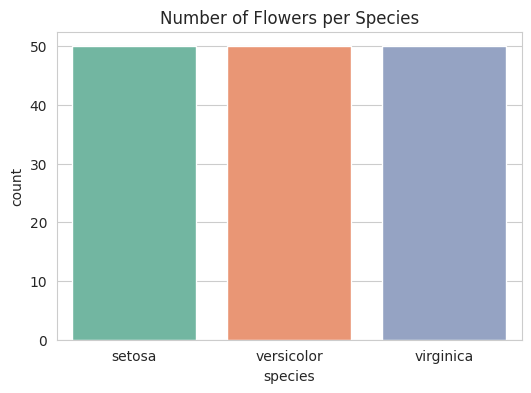

In [ ]:
# 4.1 Count of each species
plt.figure(figsize=(6, 4))
sns.countplot(x="species", data=df, palette="Set2")
plt.title("Number of Flowers per Species")
plt.show()

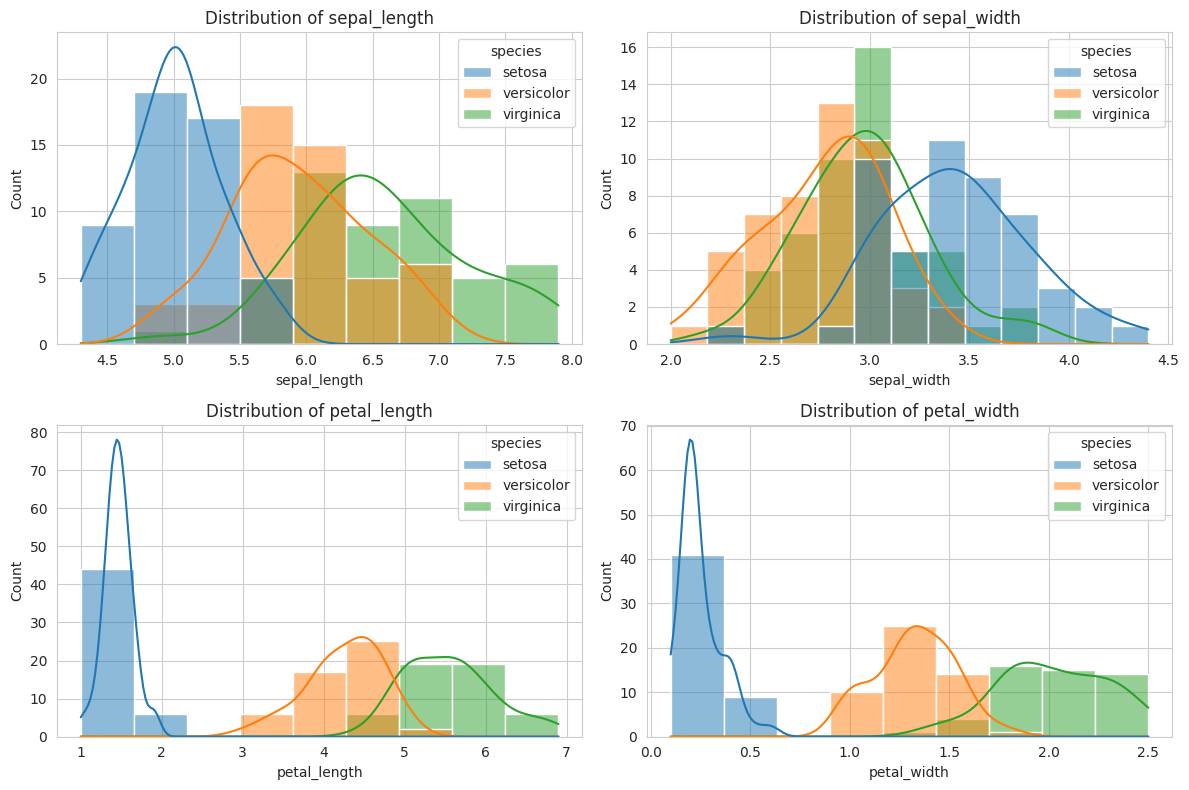

In [ ]:
# 4.2 Distribution of every measurement, split by species
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
for ax, col in zip(axes.flatten(), features):
    sns.histplot(data=df, x=col, hue="species", kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

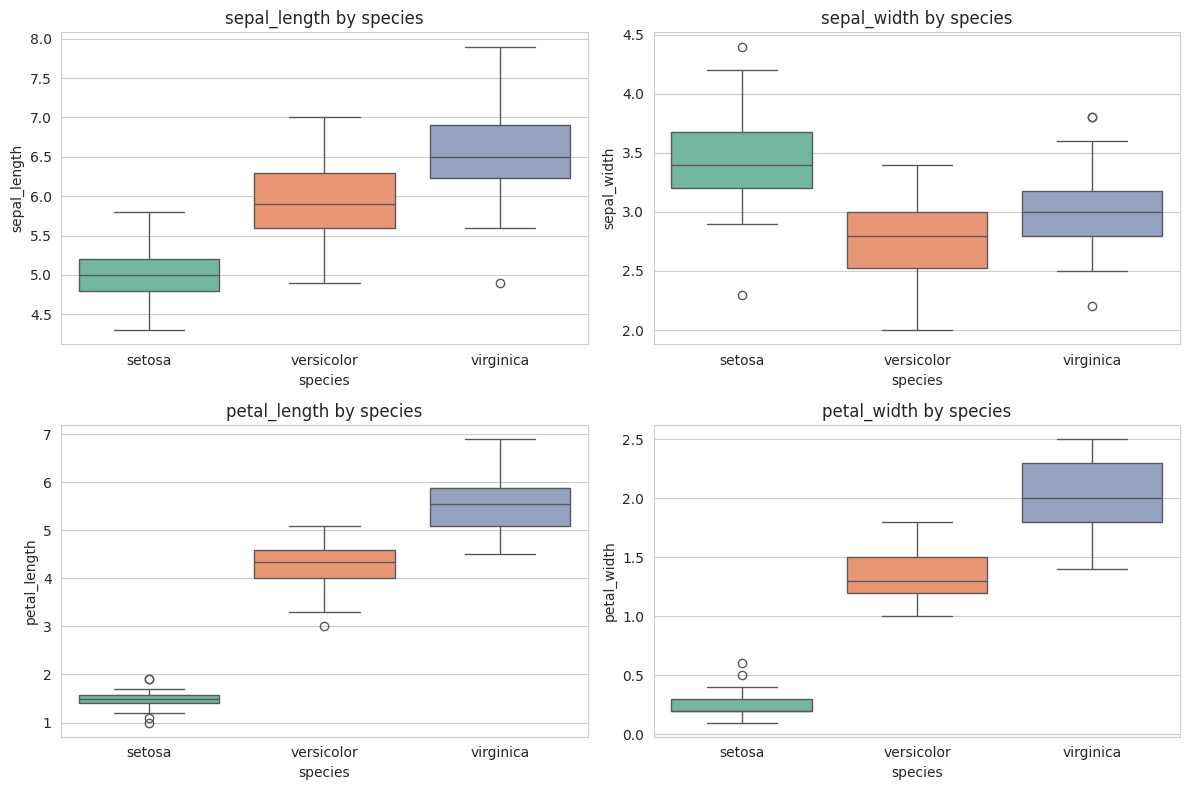

In [ ]:
# 4.3 Box plots: show the spread of each feature and any outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(x="species", y=col, data=df, palette="Set2", ax=ax)
    ax.set_title(f"{col} by species")
plt.tight_layout()
plt.show()

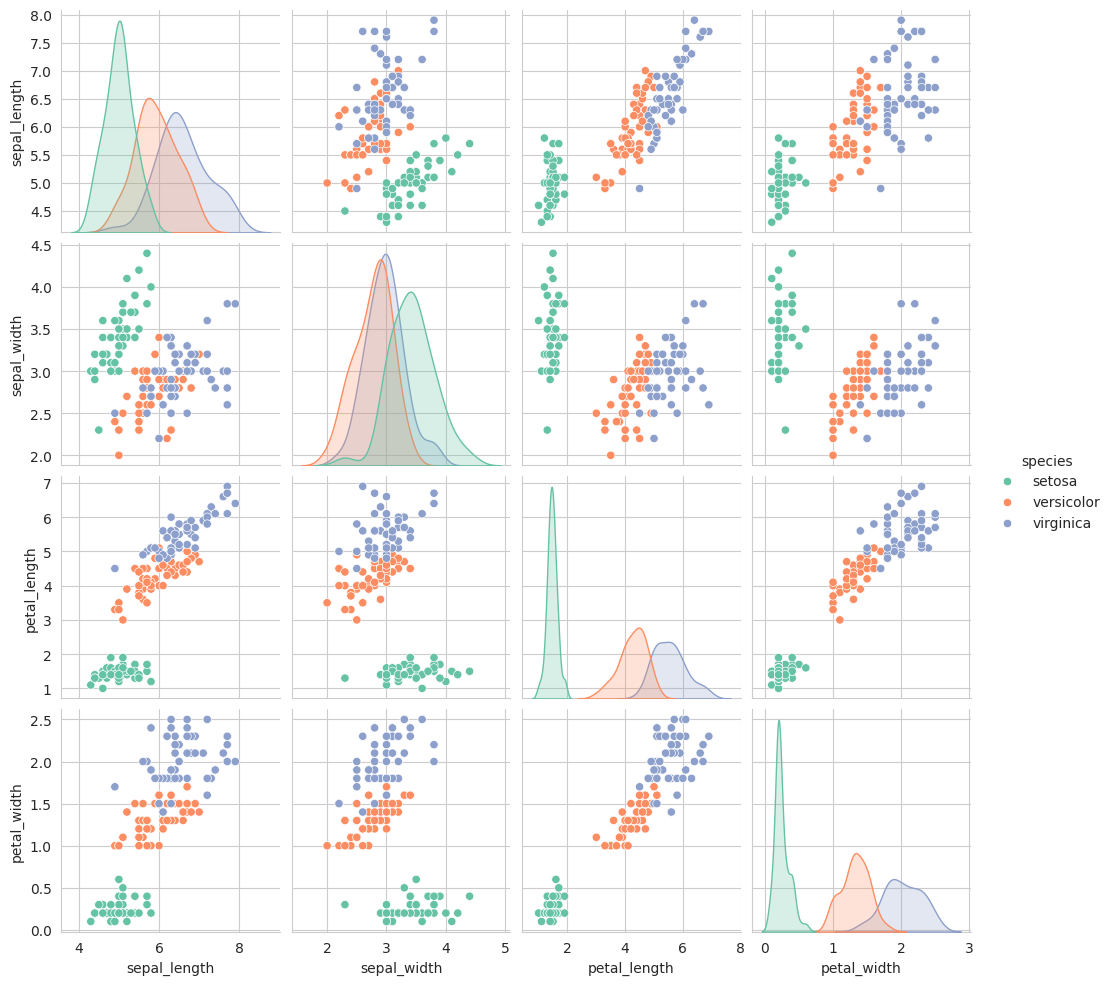

In [ ]:
# 4.4 Pair plot: every feature against every other feature
sns.pairplot(df, hue="species", palette="Set2")
plt.show()

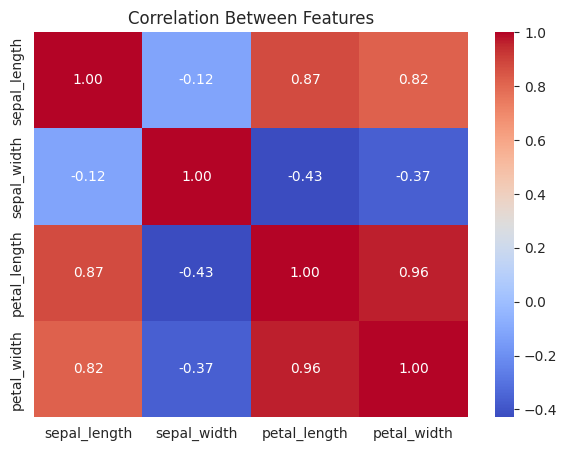

In [ ]:
# 4.5 Correlation heatmap (how strongly features move together; 1 = perfectly)
plt.figure(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Features")
plt.show()

**EDA Observations**
- *Setosa* is clearly separated from the other two species, especially by small petals.
- *Versicolor* and *virginica* overlap slightly, so they are harder to tell apart.
- Petal length and petal width are the most useful features and are highly correlated with each other.

## 5. Preprocessing
We split the data into **features (X)** (the inputs) and **target (y)** (what we want to predict), then divide it into a training set and a test set.

In [ ]:
# X = measurements, y = species name
X = df[features]
y = df["species"]

# 80% of data to train, 20% to test.
# stratify=y keeps the species proportions equal in both parts.
# random_state=42 makes the split the same every time you run it.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 120
Testing samples : 30


In [ ]:
# Feature scaling: put all features on a similar scale.
# Helps models like KNN, SVM and Logistic Regression.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn scale from training data only
X_test_scaled = scaler.transform(X_test)         # apply the same scale to test data
print("Scaling done.")

Scaling done.


## 6. Train Multiple Models
We try 5 different algorithms and compare their accuracy on the test set.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Support Vector Machine": SVC(kernel="rbf", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)          # train the model
    predictions = model.predict(X_test_scaled)  # predict on unseen test data
    results[name] = accuracy_score(y_test, predictions)
    print(f"{name:25s} Accuracy: {results[name]:.4f}")

Logistic Regression       Accuracy: 0.9333
K-Nearest Neighbors       Accuracy: 0.9333
Decision Tree             Accuracy: 0.9333
Support Vector Machine    Accuracy: 0.9667
Random Forest             Accuracy: 0.9000


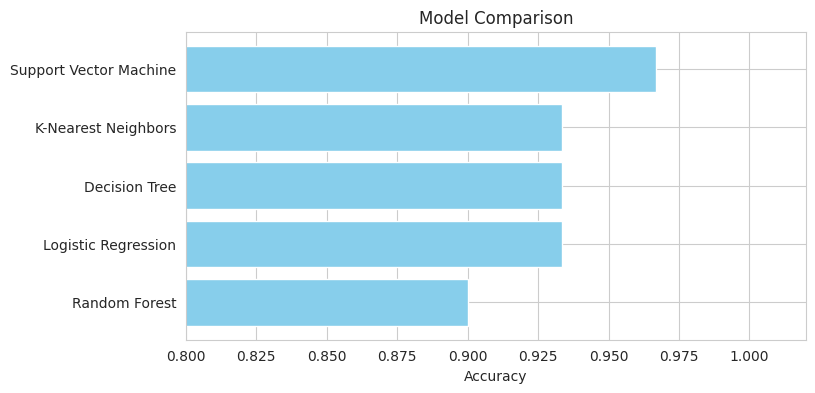

In [ ]:
# Compare models visually
res_df = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"]).sort_values("Accuracy")
plt.figure(figsize=(8, 4))
plt.barh(res_df["Model"], res_df["Accuracy"], color="skyblue")
plt.xlim(0.8, 1.02)
plt.xlabel("Accuracy")
plt.title("Model Comparison")
plt.show()

## 7. Evaluate the Best Model
Accuracy alone can hide mistakes, so we also look at the classification report and confusion matrix.

In [ ]:
# We pick Support Vector Machine as our final model (it performs very well on Iris)
final_model = SVC(kernel="rbf", random_state=42)
final_model.fit(X_train_scaled, y_train)
y_pred = final_model.predict(X_test_scaled)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
# precision = of flowers predicted as X, how many really were X
# recall    = of real X flowers, how many we found
# f1-score  = balance of precision and recall
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9667

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



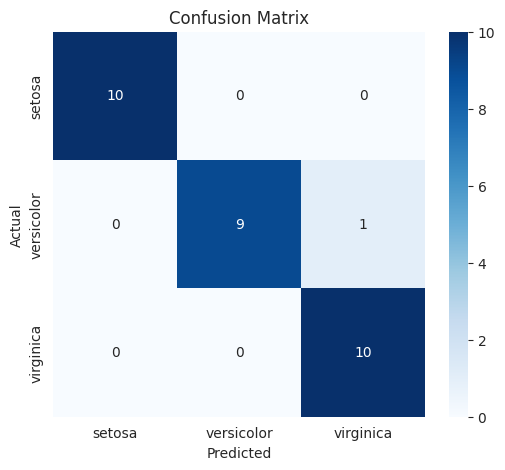

In [ ]:
# Confusion matrix: rows = real species, columns = predicted species
cm = confusion_matrix(y_test, y_pred, labels=iris_data.target_names)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris_data.target_names, yticklabels=iris_data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# Cross-validation: tests the model on 5 different splits for a more trustworthy score
scores = cross_val_score(SVC(kernel="rbf"), scaler.fit_transform(X), y, cv=5)
print("Accuracy for each fold:", np.round(scores, 3))
print("Average accuracy      :", round(scores.mean(), 4))

Accuracy for each fold: [0.967 0.967 0.967 0.933 1.   ]
Average accuracy      : 0.9667


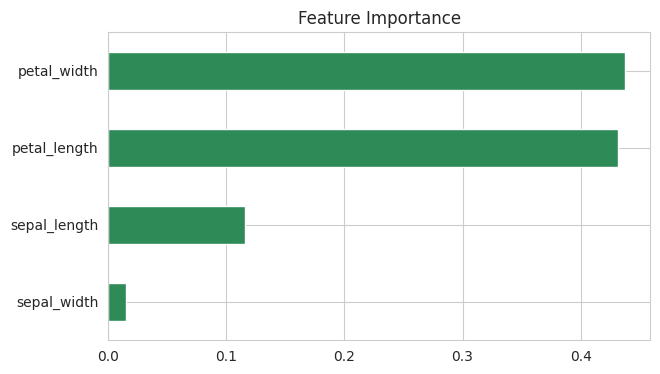

In [ ]:
# Which features matter most? (Random Forest can tell us)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="seagreen", figsize=(7, 4), title="Feature Importance")
plt.show()

## 8. Predict on New Flowers

In [ ]:
# Measurements: [sepal_length, sepal_width, petal_length, petal_width] in cm
new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],    # looks like setosa
     [6.0, 2.9, 4.5, 1.5],    # looks like versicolor
     [6.9, 3.1, 5.8, 2.1]],   # looks like virginica
    columns=features)

# Remember: scale new data with the SAME scaler
new_scaled = scaler.transform(new_flowers)
new_flowers["predicted_species"] = final_model.predict(new_scaled)
new_flowers

,sepal_length,sepal_width,petal_length,petal_width,predicted_species
0,5.1,3.5,1.4,0.2,setosa
1,6.0,2.9,4.5,1.5,versicolor
2,6.9,3.1,5.8,2.1,virginica


## 9. Conclusion
- The dataset is clean (no missing values) and balanced.
- Petal length and petal width are the strongest indicators of species.
- All five models achieved high accuracy (roughly 90% to 100% on the test set); the SVM reached about 93% to 100% depending on the split, and cross-validation gives a more reliable average of around 96% to 97%.
- Setosa is always identified correctly; the few mistakes happen between *versicolor* and *virginica*, which overlap.
- Because the dataset is small (150 rows), results can vary slightly with a different random split, which is why cross-validation is useful.

**Possible improvements:** tune hyperparameters with `GridSearchCV`, and test on more flower data.